# Practical 4: Urban air-quality sensor alert system
UCI Air Quality (hourly, Mar 2004 - Apr 2005). Unsupervised anomaly detection; Isolation Forest vs Local Outlier Factor; ensemble alert rule.
**Design rule:** the 5 low-cost metal-oxide sensors + T/RH/AH are model inputs. Reference analysers (CO(GT), C6H6(GT), NOx(GT), NO2(GT)) are used only to *validate*, never to train.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from pipeline import *
DATA='data/AirQualityUCI.csv'   # real UCI file
df=load_raw(DATA); print(df.shape, df.index.min(), df.index.max())

(9357, 13) 2004-03-10 18:00:00 2005-04-04 14:00:00


## 1. Parsing, encoded missing values, drift, seasonality
File is `;`-separated with `,` decimals, `dd/mm/yyyy` dates and `HH.MM.SS` times. `-200` is the missing-value code and is converted to NaN *before* any statistics (otherwise -200 looks like a huge negative anomaly).

NMHC(GT)         0.902
CO(GT)           0.180
NO2(GT)          0.175
NOx(GT)          0.175
PT08.S1(CO)      0.039
PT08.S2(NMHC)    0.039
C6H6(GT)         0.039
PT08.S3(NOx)     0.039
PT08.S4(NO2)     0.039
PT08.S5(O3)      0.039
T                0.039
RH               0.039
AH               0.039
dtype: float64
hours on grid: 9357 rows with all inputs missing: 366


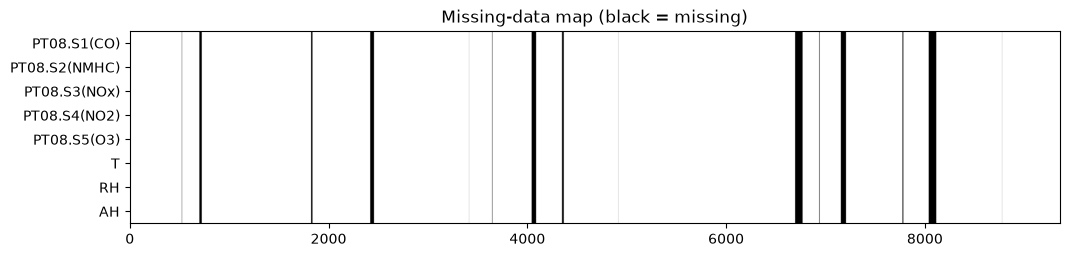

In [2]:
miss=df.isna().mean().sort_values(ascending=False).round(3); print(miss)
full=df.asfreq('h'); print('hours on grid:',len(full),'rows with all inputs missing:',df[INPUTS].isna().all(axis=1).sum())
fig,ax=plt.subplots(figsize=(12,2.5)); ax.imshow(df[INPUTS].isna().T,aspect='auto',cmap='Greys'); ax.set_yticks(range(len(INPUTS))); ax.set_yticklabels(INPUTS); ax.set_title('Missing-data map (black = missing)'); plt.show()

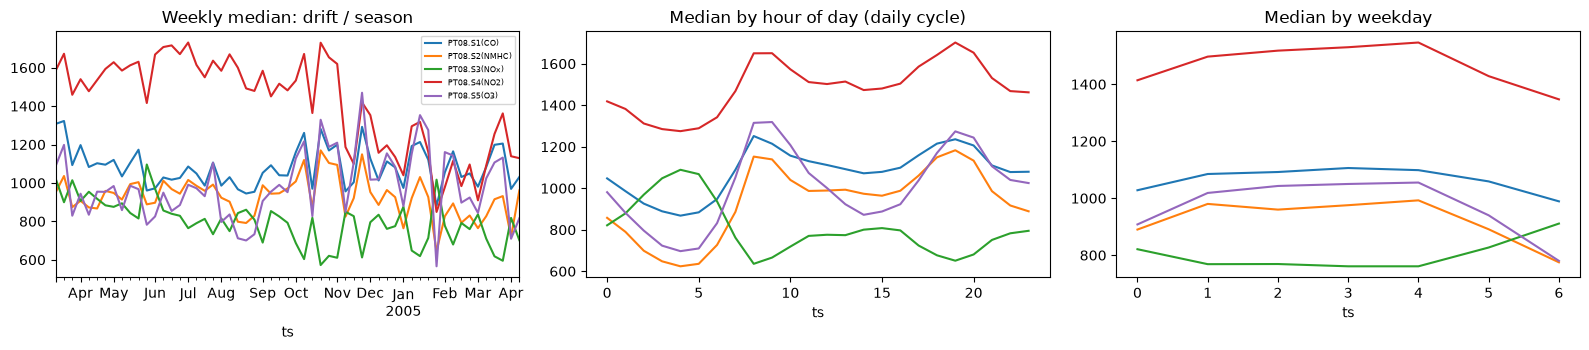

In [3]:
fig,axs=plt.subplots(1,3,figsize=(16,3.6))
df[SENSORS].resample('W').median().plot(ax=axs[0],title='Weekly median: drift / season'); axs[0].legend(fontsize=6)
df[SENSORS].groupby(df.index.hour).median().plot(ax=axs[1],title='Median by hour of day (daily cycle)'); axs[1].legend().remove()
df[SENSORS].groupby(df.index.dayofweek).median().plot(ax=axs[2],title='Median by weekday'); axs[2].legend().remove(); plt.tight_layout(); plt.show()

**Reading the plots.** Slow shifts in the weekly medians are sensor drift and seasonality (temperature/humidity cross-sensitivity of metal-oxide sensors); the hour-of-day curve shows rush-hour peaks. A model on raw values would flag *winter* as anomalous. So features are measured relative to each sensor's own recent baseline (24 h and 168 h trailing medians).

## 2. Causal features (no future data)
For each input: raw value, deviation from trailing 24 h median, deviation from trailing 168 h median (drift-robust), 1 h and 3 h change, 6 h rolling std; plus cyclic hour/weekday and a 24 h missing-data fraction. Rolling windows end at the current hour.

In [4]:
F=make_features(df)
# causality test: features at time t must not change if all later data is deleted
t=pd.Timestamp('2004-11-15 12:00'); F2=make_features(df.loc[:t])
assert np.allclose(F.loc[t].values.astype(float),F2.loc[t].values.astype(float),equal_nan=True); print('causality check passed; n features =',F.shape[1])

causality check passed; n features = 53


## 3. Model comparison
Train Mar-Jun 2004, **calibrate** (score percentiles) on July 2004, test Aug 2004 onwards. Percentiles are measured against out-of-sample calibration scores (LOF in-sample scores would be biased).

In [5]:
tr,cal,te=F[:'2004-07-01'],F['2004-07-01':'2004-07-29'],F['2004-07-29':]
det=AirQualityDetector().fit(tr,cal); sc=det.score(F); T=sc.loc['2004-07-29':]
ok=T.scored
print('Spearman IF vs LOF:',round(spearmanr(T.s_if[ok],T.s_lof[ok])[0],3))
for r in (.01,.02):
    a,b=top_flags(T.s_if,r),top_flags(T.s_lof,r); print(f'top {r:.0%}: IF flags {a.sum()}, LOF flags {b.sum()}, Jaccard overlap {jaccard(a,b):.2f}')

Spearman IF vs LOF: 0.466
top 1%: IF flags 57, LOF flags 57, Jaccard overlap 0.10
top 2%: IF flags 113, LOF flags 113, Jaccard overlap 0.10


## 4. Evaluation without verified labels
**(a) Proxy rule.** A proxy event is an hour where any reference analyser exceeds its *training-period* 95th percentile (the sensors are meant to track these gases). This is imperfect: it contains normal rush-hour peaks and ignores faults, so treat it as *relative* evidence (lift over base rate), not accuracy.

In [6]:
ev=proxy_events(df,df.loc[:'2004-07-01']).loc['2004-07-29':]; base=ev[ok].mean(); print('proxy base rate',round(base,3))
rows=[]
for name,s in [('IsolationForest',T.s_if),('LOF',T.s_lof),('Ensemble(mean pct)',(T.p_if+T.p_lof)/2)]:
    for r in (.01,.02,.05):
        f=top_flags(s,r)&ok; rows.append(dict(model=name,flag_rate=r,flags=int(f.sum()),precision=round(ev[f].mean(),3),lift=round(ev[f].mean()/base,2),recall=round((f&ev).sum()/ev[ok].sum(),3)))
print(pd.DataFrame(rows).to_string(index=False))

proxy base rate 0.394
             model  flag_rate  flags  precision  lift  recall
   IsolationForest       0.01     57      0.807  2.05   0.021
   IsolationForest       0.02    113      0.796  2.02   0.041
   IsolationForest       0.05    282      0.738  1.87   0.094
               LOF       0.01     57      0.281  0.71   0.007
               LOF       0.02    113      0.310  0.79   0.016
               LOF       0.05    282      0.340  0.86   0.043
Ensemble(mean pct)       0.01     59      0.271  0.69   0.007
Ensemble(mean pct)       0.02    118      0.415  1.05   0.022
Ensemble(mean pct)       0.05    282      0.447  1.13   0.057


**(b) Visual inspection.** Plot the top-ranked windows and check that flagged hours look different from the surrounding days.

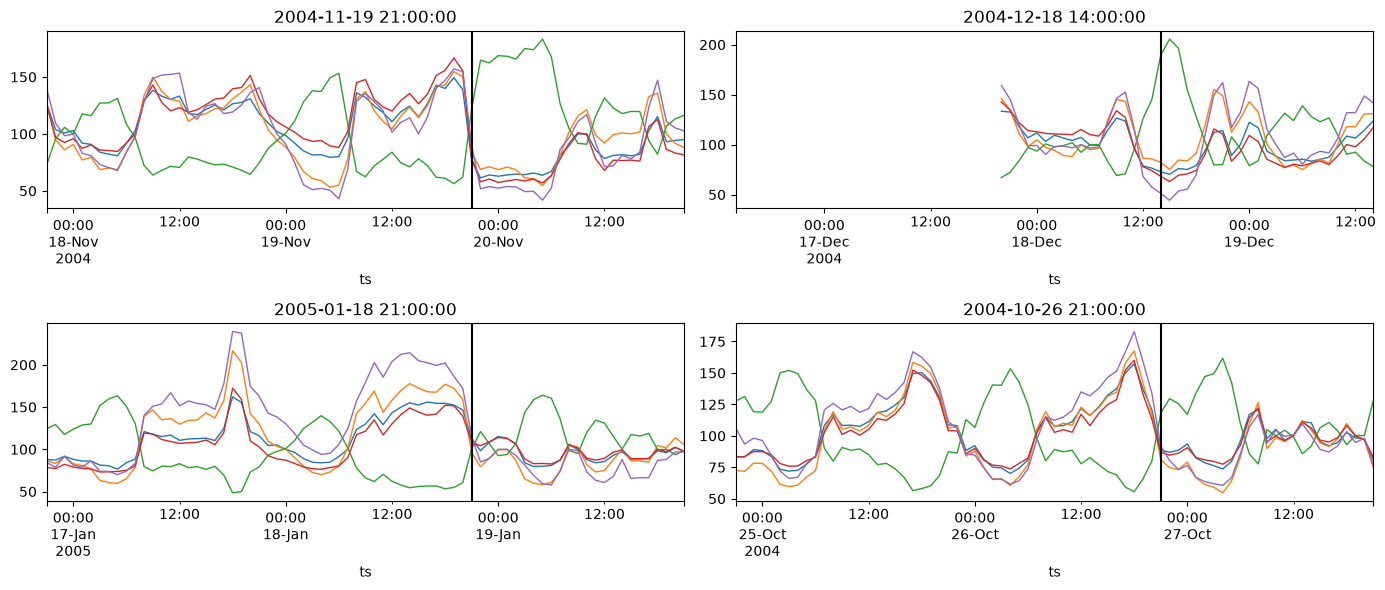

In [7]:
top=T.assign(e=(T.p_if+T.p_lof)/2).e.nlargest(300).index; first=[top[0]]
for t in top[1:]:
    if all(abs((t-u).total_seconds())>48*3600 for u in first): first.append(t)
    if len(first)==4: break
fig,axs=plt.subplots(2,2,figsize=(14,6))
for ax,t in zip(axs.ravel(),first):
    w=df.loc[t-pd.Timedelta(hours=48):t+pd.Timedelta(hours=24),SENSORS]; (100*w/w.median()).plot(ax=ax,legend=False,lw=1); ax.axvline(t,color='k'); ax.set_title(str(t))
plt.tight_layout(); plt.show()

**(c) Stability across time windows.** Refit on 5 rolling windows (90 d train / 28 d calibrate / 28 d test). Stable methods flag similar *numbers* of hours and agree with each other; unstable ones do not.

In [8]:
rows=[];prev=None
for start,s in rolling_origin(df,n_windows=6,step_days=30):
    a,b=top_flags(s.s_if,.01),top_flags(s.s_lof,.01); ens=(s.p_if>=.99)&(s.p_lof>=.99)
    rows.append(dict(test_start=start.date(),IF_p99_rate=round((s.p_if>=.99).mean(),3),LOF_p99_rate=round((s.p_lof>=.99).mean(),3),both_agree_rate=round(ens.mean(),4),jaccard_IF_LOF=round(jaccard(a,b),2)))
print(pd.DataFrame(rows).to_string(index=False))

test_start  IF_p99_rate  LOF_p99_rate  both_agree_rate  jaccard_IF_LOF
2004-07-06        0.006         0.012           0.0000             0.0
2004-08-05        0.006         0.006           0.0000             0.0
2004-09-04        0.042         0.070           0.0059             0.0
2004-10-04        0.003         0.007           0.0000             0.0
2004-11-03        0.033         0.095           0.0104             0.4
2004-12-03        0.007         0.015           0.0000             0.0


A p99 threshold calibrated on one month should flag about 1 % in later windows; rates drifting far above that indicate sensor drift/seasonal shift and are the trigger for recalibration (see monitoring procedure in README).

## 5. Alert rule and false-alarm load
Rule (`AirQualityDetector.alert`): **WATCH** both models >= p99; **ALERT** both >= p99.5 and persistent (>=2 of last 3 h); **CRITICAL** both >= p99.9 and >=3 sensors moved together; **SENSOR_FAULT** flatline (>=6 identical h) routed to maintenance; **NO_DATA** when history is missing.

In [9]:
R=det.alert(sc).loc['2004-07-29':]; weeks=len(R)/168
print(R.severity.value_counts()); print('\nper week -> naive single-model top1%:',round(top_flags(T.s_if,.01).sum()/weeks,1),'| WATCH+:',round(R.severity.isin(['WATCH','ALERT','CRITICAL']).sum()/weeks,1),'| ALERT+:',round(R.severity.isin(['ALERT','CRITICAL']).sum()/weeks,1))
print(R[R.severity.isin(['ALERT','CRITICAL','SENSOR_FAULT'])].groupby(['severity','cause']).size())

severity
NONE       5623
NO_DATA     357
ALERT         7
WATCH         4
Name: count, dtype: int64

per week -> naive single-model top1%: 1.6 | WATCH+: 0.3 | ALERT+: 0.2
severity  cause                                      
ALERT     possible sensor fault (single sensor moved)    2
          unusual pattern / meteorology shift            5
dtype: int64


## 6. Sample alerts with explanations

In [10]:
ex=R[R.severity.isin(['CRITICAL','ALERT','SENSOR_FAULT'])]
for t in list(ex.index[:: max(1,len(ex)//5)])[:5]:
    r=R.loc[t]; print(f'\n{t}  {r.severity}  | {r.cause} | pIF={r.p_if:.4f} pLOF={r.p_lof:.4f}')
    if r.scored:
        for line in det.explain(df.loc[:t],t)['text']: print('   -',line)


2004-11-19 22:00:00  ALERT  | unusual pattern / meteorology shift | pIF=1.0000 pLOF=1.0000
   - AH: 0 now, -1 vs 24h median, -1 over 3h (share of score 44%)
   - PT08.S4(NO2): 709 now, -782 vs 24h median, -1331 over 3h (share of score 15%)
   - RH: 14 now, -44 vs 24h median, -48 over 3h (share of score 15%)

2004-11-19 23:00:00  ALERT  | unusual pattern / meteorology shift | pIF=1.0000 pLOF=1.0000
   - AH: 0 now, -1 vs 24h median, -1 over 3h (share of score 33%)
   - PT08.S4(NO2): 739 now, -752 vs 24h median, -1162 over 3h (share of score 16%)
   - PT08.S1(CO): 695 now, -530 vs 24h median, -815 over 3h (share of score 15%)

2004-11-20 00:00:00  ALERT  | unusual pattern / meteorology shift | pIF=1.0000 pLOF=1.0000
   - PT08.S4(NO2): 702 now, -789 vs 24h median, -258 over 3h (share of score 19%)
   - AH: 0 now, -1 vs 24h median, -0 over 3h (share of score 18%)
   - PT08.S1(CO): 683 now, -542 vs 24h median, -154 over 3h (share of score 18%)

2004-11-20 01:00:00  ALERT  | unusual pattern 

## 7. Limits
The proxy rule is imperfect, there are no verified fault labels, one year spans every season once, and the sensors themselves drift. See README for uncertainty, cost of missed events and monitoring procedure.

In [12]:
!python train.py data/AirQualityUCI.csv


saved; train end 2004-07-01 23:00:00
